# **A behavioural portfolio dashboard for an individual investor**
## **Integrative Project — Behavioural Finance**

---

**Authors:** Alan Jesús Hernández Soto · Francisco Uriel Ledezma Chávez · Esteban Vega Campos · Santiago Villegas Baltazar
**Programme:** Ingeniería Financiera
**Institution:** ITESO — Universidad Jesuita de Guadalajara
**Course:** Comportamiento en las Finanzas y Toma de Decisiones
**Professor:** Luis Felipe Gómez Estrada
**Date:** 24 November 2026

---

## Contents

0. [The project in plain terms](#s0)
1. [Part 1: the client profile](#s1)
   - [1.1 The instrument](#s11)
   - [1.2 What the estimators are, and why in that order](#s12)
   - [1.3 Checking the implementation against the course's own numbers](#s13)
2. [Part 2: portfolio construction](#s2)
   - [2.1 The model](#s21)
   - [2.2 What the optimiser does to an estimated mean](#s22)
   - [2.3 The portfolio this client is given](#s23)
3. [Part 3: the sequential decision problem](#s3)
   - [3.1 Step 1: the narrative](#s31)
   - [3.2 Step 2: core elements](#s32)
   - [3.3 Step 3: the mathematical model](#s33)
   - [3.4 Step 4: the uncertainty model](#s34)
   - [3.5 Step 5: designing policies](#s35)
   - [3.6 Step 6: evaluating policies](#s36)
4. [Results](#s4)
5. [Robustness, and what would change the recommendation](#s5)
6. [Recommendation to the client](#s6)
7. [Limitations](#s7)
8. [References](#s8)

<a id="s0"></a>

## 0. The project in plain terms

An advisory firm wants to tell a client three things at once: what kind of risk taker they are, what portfolio that implies, and what their own habits will cost them if they keep them. The first is a measurement problem, the second an optimisation problem, and the third a sequential decision problem, and this report does them in that order because each one feeds the next.

The measurement is ten questions whose answers identify the three parameters of a prospect-theory value function, using the corrected estimator the course's own appendix gives rather than the one its body page uses. The optimisation is a mixed-integer programme that picks at most ten funds out of twenty five subject to minimum lots and a cap on each asset class, and whose risk aversion is set by the client's own loss aversion. The decision problem is ten years of months in which six policies, two of them written to imitate the client rather than to help them, are run over the same simulated scenarios so that any difference between them is the policy and not the draw.

In [1]:
# A kernel left running keeps the version of the package it first imported, and
# "Run All" does not restart it, so an edit to src/ would otherwise go unseen.
%load_ext autoreload
%autoreload 2

import os, sys, pathlib, warnings

HERE = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "src" / "bpd").is_dir())
os.chdir(HERE)
sys.path.insert(0, str(HERE / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bpd import config, data, evaluate, policies, portfolio, profile, questionnaire, simulator

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

<a id="s1"></a>

## 1. Part 1: the client profile

<a id="s11"></a>

### 1.1 The instrument

Ten questions. The first four are lotteries whose answers identify the value function, the fifth fixes the reference point, and the last five are scenarios that set the behavioural flags, each of which names the policy it switches on in Part 3.

The lottery used for loss aversion is the opening exercise of the course's prospect-theory lecture, a fair coin that loses a thousand pesos on heads and pays an unknown gain on tails, and the client is asked for the smallest gain at which they would take it. We put the question as a ladder of concrete bets rather than as an open number, which is a design choice of ours and not one the course makes: the lecture asks for the number directly. The consequence is measurable rather than psychological, since a ladder brackets the switch point instead of locating it, so the midpoint of the bracket is used and the estimate inherits the spacing of the rungs.

**The client quoted throughout this report is a constructed example, not a person who was interviewed.** The three certainty equivalents are the exact inversions of the curvature formula at the published 0.88, so the curvatures come back at 0.88 by construction. The ladder answer of 2,600 brackets to 2,400, which gives 2.16 on the body's formula and **2.00 once the appendix's correction is applied**, and every behavioural flag is set on purpose so that the policies of Part 3 have something to act on. A real client would produce different numbers and the dashboard exists so that they can.

In [2]:
for item in questionnaire.QUESTIONS:
    print(f"{item['id']:<18}{item['measures']}")
    print(f"{'':18}{item['text']}")

q1_ladder         loss aversion
                  A fair coin is flipped. Heads you lose $1,000. Tails you win G. What is the smallest G at which you would take the bet?
q2_gain_ce        curvature over gains
                  A fair coin is flipped. Heads you win $10,000, tails you win nothing. What certain amount would you accept instead of the bet?
q3_loss_ce        curvature over losses
                  A fair coin is flipped. Heads you lose $10,000, tails you lose nothing. What certain loss would you accept instead of the bet?
q4_gain_ce_small  curvature, consistency check
                  The same bet at a smaller stake. Heads you win $2,000, tails nothing. What certain amount would you accept instead?
q5_reference      reference point
                  Ten years from now, which number will you compare your portfolio against?
q6_drawdown       panic selling
                  Your portfolio has fallen 20% in three months. What do you do?
q7_chasing        performance chasing
   

<a id="s12"></a>

### 1.2 What the estimators are, and why in that order

The three parameters are identified in the order $\beta$, $\alpha$, $\lambda$. Only the last position is forced by the algebra; the two curvatures could be taken in either order, and they are taken from their own arms for clarity rather than from necessity.

A loss-only lottery paying nothing or $-X$ with equal probability has prospect-theory value $-\tfrac{1}{2}\lambda X^{\beta}$, and the certain loss $c$ the client would accept instead satisfies $-\lambda c^{\beta} = -\tfrac{1}{2}\lambda X^{\beta}$. Loss aversion appears on both sides and cancels, which leaves $\beta = \ln(0.5) / \ln(c/X)$ and identifies curvature over losses without knowing $\lambda$ at all. The gain-only lottery gives $\alpha$ the same way. Only then does the mixed lottery identify loss aversion, through $\tfrac{1}{2} G^{\alpha} = \tfrac{1}{2}\lambda L^{\beta}$, so that $\lambda = G^{\alpha} / L^{\beta}$, which at $\alpha = \beta = 0.88$ and $L = 1000$ is the course's own $\hat\lambda = (G/1000)^{0.88}$.

The lecture writes that indifference condition with one half on both sides, and its appendix then withdraws it. Page 31 says plainly that the estimate so obtained **is biased**, because the two decision weights are not equal at a half: $w^{+}(0.5) = 0.421$ against $w^{-}(0.5) = 0.454$. The corrected identity multiplies by their ratio,

$$
\hat\lambda \;=\; \frac{w^{+}(0.5)}{w^{-}(0.5)} \cdot \frac{G^{\alpha}}{L^{\beta}},
$$

which is about 7% lower, and the appendix's own worked case has $G = 2{,}500$ giving 2.08 rather than 2.24. We apply the correction, because quoting the figure the course itself calls biased would be the first thing worth attacking in this report. Both values are computed below so the size of the correction is visible rather than buried.

The same appendix adds the limitation that no amount of arithmetic removes: loss aversion and probability weighting are not separately identified from a single indifference, so any measured $\lambda$ carries assumptions about $w$, and any measured $w$ carries assumptions about $\alpha$. It notes that a trade-off ladder which cancels $w$ before estimating $v$ is what a serious elicitation uses. Ours is a ladder, but it brackets the switch point rather than cancelling the weights, so it does not buy that property and this report does not claim it.

In [3]:
answers = questionnaire.default_answers()
client = questionnaire.score(answers)

gain = questionnaire._bracket_midpoint(answers["q1_ladder"])
naive = profile.loss_aversion_from_g(gain, client.alpha, client.beta, corrected=False)
print(f"ladder answer {answers['q1_ladder']:,.0f}, bracket midpoint {gain:,.0f}")
print(f"lambda uncorrected {naive:.3f}   the deck's body formula")
print(f"lambda corrected   {client.lam:.3f}   the appendix's, lower by "
      f"{100 * (naive - client.lam) / naive:.1f}%")
print()
print(f"alpha  {client.alpha:.3f}   curvature over gains")
print(f"beta   {client.beta:.3f}   curvature over losses")
print(f"lambda {client.lam:.3f}   loss aversion")
print(f"gamma  {client.gamma:.2f}    risk aversion handed to Part 2")
print(f"reference point: {client.reference}")
print()
for name, on in client.flags.items():
    print(f"{name:<22}{'yes' if on else 'no'}")

ladder answer 2,600, bracket midpoint 2,400
lambda uncorrected 2.161   the deck's body formula
lambda corrected   2.002   the appendix's, lower by 7.3%

alpha  0.880   curvature over gains
beta   0.880   curvature over losses
lambda 2.002   loss aversion
gamma  5.76    risk aversion handed to Part 2
reference point: A target I have in mind

panic_selling         yes
performance_chasing   yes
disposition           yes
narrow_framing        yes
anchoring             yes


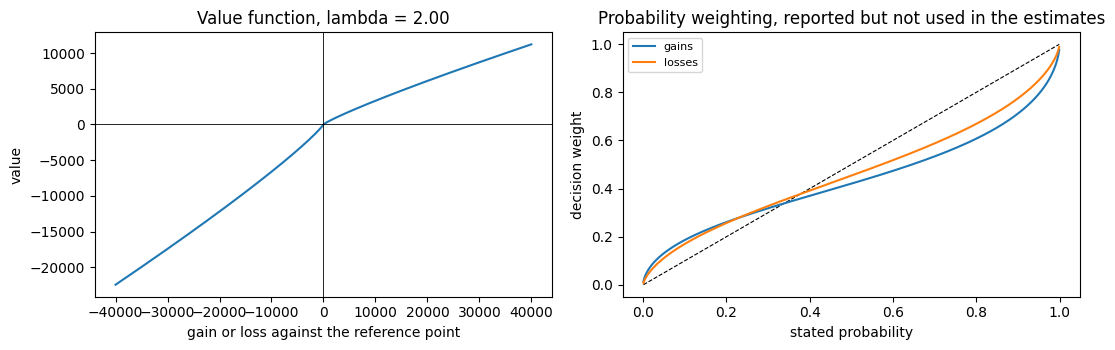

In [4]:
grid = np.linspace(-40_000, 40_000, 400)
probabilities = np.linspace(0.001, 0.999, 400)

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
left.plot(grid, profile.value(grid, client.alpha, client.beta, client.lam))
left.axhline(0, linewidth=0.6, color="black")
left.axvline(0, linewidth=0.6, color="black")
left.set_xlabel("gain or loss against the reference point")
left.set_ylabel("value")
left.set_title(f"Value function, lambda = {client.lam:.2f}")

right.plot(probabilities, probabilities, linewidth=0.8, linestyle="--", color="black")
right.plot(probabilities, profile.weight(probabilities, config.GAMMA_PLUS), label="gains")
right.plot(probabilities, profile.weight(probabilities, config.GAMMA_MINUS), label="losses")
right.set_xlabel("stated probability")
right.set_ylabel("decision weight")
right.set_title("Probability weighting, reported but not used in the estimates")
right.legend(fontsize=8)
plt.tight_layout()
plt.savefig("results/figures/profile.png", dpi=120)
plt.show()

<a id="s13"></a>

### 1.3 Checking the implementation against the course's own numbers

An estimator that is wrong in the third decimal still produces a confident profile, so the implementation is checked against values that were published before we wrote it. The table below reproduces the loss-aversion ladder, the decision weights and the worked examples from the course's prospect-theory lecture, including both the body's estimate of 2.24 and the appendix's corrected 2.08 for the same answer, and the test suite asserts every one of them.

In [5]:
A = B = config.ALPHA_TK
naive = lambda g: profile.loss_aversion_from_g(g, A, B, corrected=False)
checks = [
    ("lambda at G = 1500, body", naive(1500), 1.43),
    ("lambda at G = 2000, body", naive(2000), 1.84),
    ("lambda at G = 2500, body", naive(2500), 2.24),
    ("lambda at G = 3000, body", naive(3000), 2.63),
    ("lambda at G = 2513, body", naive(2513), 2.25),
    ("w+(0.50)", profile.weight(0.50, config.GAMMA_PLUS), 0.421),
    ("w-(0.50)", profile.weight(0.50, config.GAMMA_MINUS), 0.454),
    ("w+(0.10)", profile.weight(0.10, config.GAMMA_PLUS), 0.186),
    ("w+(0.90)", profile.weight(0.90, config.GAMMA_PLUS), 0.712),
    ("v(-400)", profile.value(-400, A, B, 2.25), -438.5),
    ("half of v(-800)", 0.5 * profile.value(-800, A, B, 2.25), -403.5),
    ("note: v(-20,000)", profile.value(-20_000, A, B, 2.25), -13_712),
    ("note: v(+25,000)", profile.value(25_000, A, B, 2.25), 7_416),
    ("lambda at G = 2500, body", profile.loss_aversion_from_g(2500, A, B, corrected=False), 2.24),
    ("lambda at G = 2500, appendix", profile.loss_aversion_from_g(2500, A, B, corrected=True), 2.08),
]
rows = [{"quantity": name, "ours": value, "course": published,
         "agrees": abs(value - published) <= max(0.005, abs(published) * 0.0005)}
        for name, value, published in checks]
print(pd.DataFrame(rows).to_string(index=False))
print()
print(f"all {len(rows)} agree: {all(r['agrees'] for r in rows)}")

                    quantity                ours     course  agrees
    lambda at G = 1500, body            1.428763      1.430    True
    lambda at G = 2000, body            1.840375      1.840    True
    lambda at G = 2500, body            2.239686      2.240    True
    lambda at G = 3000, body            2.629461      2.630    True
    lambda at G = 2513, body            2.249932      2.250    True
                    w+(0.50)            0.420639      0.421    True
                    w-(0.50)            0.453988      0.454    True
                    w+(0.10)            0.186303      0.186    True
                    w+(0.90)            0.711716      0.712    True
                     v(-400)  -438.5259625377816   -438.500    True
             half of v(-800)         -403.526175   -403.500    True
            note: v(-20,000) -13711.624592663055 -13712.000    True
            note: v(+25,000)  7416.2986048930625   7416.000    True
    lambda at G = 2500, body            2.239686

<a id="s2"></a>

## 2. Part 2: portfolio construction

<a id="s21"></a>

### 2.1 The model

The objective is mean-variance in the utility form the course uses, maximising $w^{\top}\mu - \tfrac{\gamma}{2} w^{\top}\Sigma w$ subject to the weights summing to one. The brief offers mean-CVaR as an alternative and we did not take it, because mean-variance is the objective the course develops, audits and criticises at length while conditional value at risk appears nowhere in its material, and an objective we could not defend from the course would be the weakest part of the report.

Four constraints turn it into a mixed-integer programme. A binary $z_i$ marks whether fund $i$ is held at all; at most $K$ of them may be one; a held position is at least $l$ and at most $u$ of the portfolio, written $l z_i \le w_i \le u z_i$ so that one pair of inequalities enforces the lot size and the link to the binary at the same time; and the weight of each asset class is capped.

Risk aversion is not asked for. It is set from the client's loss aversion, linearly between two anchors as $\lambda$ runs across the range the course reports for published estimates. That map is ours rather than the course's, and section 7 lists it with the other four decisions of the same kind.

In [6]:
prices = data.load_prices()
rets = data.monthly_returns(prices)
mu, sigma = data.moments(rets)
classes = [config.ASSET_CLASS[t] for t in config.TICKERS]

print(f"{len(rets)} monthly returns, {rets.index[0].date()} to {rets.index[-1].date()}, "
      f"{rets.shape[1]} funds, no missing values: {not rets.isna().any().any()}")
print(f"asset classes: {', '.join(config.CLASSES)}")

129 monthly returns, 2016-02-29 to 2026-10-31, 25 funds, no missing values: True
asset classes: Cash, Fixed income, Non-US equity, Real assets, US equity


<a id="s22"></a>

### 2.2 What the optimiser does to an estimated mean

The course spends a lecture on why this model misbehaves, and the misbehaviour is not a bug to be fixed but a property to be managed, so it is worth stating before the portfolio is shown rather than after.

Three results from that lecture apply directly. Merton's shows that the standard error of an estimated mean is $\sigma/\sqrt{T}$ and depends only on the calendar span of the sample, so no amount of higher-frequency data improves it, and the lecture tabulates over a thousand years of US large-cap history as the span needed to pin a mean to fifty basis points. Chopra and Ziemba's shows that errors in means cost about ten times what errors in covariances cost, so effort spent cleaning $\Sigma$ is effort spent on the input that matters least. Michaud's names what follows: the optimiser prefers assets with a high estimated mean, a low estimated variance and a low estimated correlation, which are exactly the assets most likely to be carrying a positive estimation error, so the objective and the error point the same way.

Our response takes the lecture's principle and applies it to a different input, which is a departure worth stating rather than glossing. Jagannathan and Ma show that a binding long-only constraint is algebraically identical to shrinking the covariance matrix, so a long-only optimiser that behaves well is running an undocumented shrinkage estimator, and the lecture's advice is to shrink deliberately instead, naming an explicit covariance target or an explicit prior on returns as the two ways to do it. We do neither of those exactly. We shrink the **mean** toward its cross-sectional average, at an intensity of 0.50, and leave the covariance as the sample covariance, because the same lecture ranks errors in means at ten times the cost of errors in covariances and it would be odd to regularise the cheap input while leaving the expensive one raw. The report shows what the whole range of that intensity does, so a reader who disagrees with 0.50 can read off the alternative.

At an intensity of one every fund has the same expected mean, the programme has nothing left to maximise but the quadratic term, and it returns the minimum-variance portfolio **subject to the cardinality, lot and class constraints**, which is not the unconstrained global minimum-variance portfolio of the lecture but is the same idea: the frontier portfolio that refuses to use the input it cannot estimate.

In [7]:
rows = []
for shrink in (0.0, 0.25, 0.50, 0.75, 1.0):
    mu_s, sigma_s = data.moments(rets, shrink=shrink)
    w_s, report_s = portfolio.solve(mu_s, sigma_s, classes, client.gamma / 2.0)
    held = [(config.TICKERS[i], w_s[i]) for i in np.argsort(-w_s) if w_s[i] > 1e-9]
    rows.append({"shrink": shrink, "holdings": report_s["held"],
                 "largest": w_s.max(),
                 "expected a year": report_s["expected_monthly"] * 12,
                 "volatility a year": report_s["monthly_vol"] * np.sqrt(12),
                 "portfolio": ", ".join(f"{t} {100 * v:.0f}" for t, v in held)})
shrink_table = pd.DataFrame(rows)
print(shrink_table.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

Restricted license - for non-production use only - expires 2028-11-29


 shrink  holdings  largest  expected a year  volatility a year                                                       portfolio
  0.000         6    0.350            0.155              0.114                    XLK 35, GLD 26, DBC 14, EFA 12, BIL 8, QQQ 5
  0.250         6    0.350            0.134              0.099                    XLK 35, GLD 26, BIL 20, DBC 14, QQQ 3, XLE 2
  0.500         5    0.341            0.121              0.095                           XLK 34, GLD 24, BIL 20, DBC 16, XLV 6
  0.750         6    0.350            0.099              0.059                   BIL 35, XLK 18, GLD 16, SHY 12, DBC 12, XLV 7
  1.000         9    0.350            0.101              0.027 BIL 35, SHY 35, DBC 8, GLD 5, IEF 5, XLV 5, XLP 3, XLK 2, XLU 2

<a id="s23"></a>

### 2.3 The portfolio this client is given

In [8]:
target, build_report = portfolio.solve(mu, sigma, classes, client.gamma / 2.0)
held = pd.DataFrame({"fund": config.TICKERS, "asset class": classes, "weight": target})
held = held[held.weight > 1e-9].sort_values("weight", ascending=False)
print(held.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print()
print(f"holdings {build_report['held']} of at most {config.K_MAX}, "
      f"weights sum to {target.sum():.6f}, smallest held position {held.weight.min():.3f} "
      f"against a minimum lot of {config.MIN_POSITION}")
print(f"expected {build_report['expected_monthly'] * 12:.2%} a year, "
      f"volatility {build_report['monthly_vol'] * np.sqrt(12):.2%} a year, "
      f"optimality gap {build_report['gap']:.4f}")
print()
by_class = held.groupby("asset class").weight.sum().sort_values(ascending=False)
print(by_class.to_string(float_format=lambda v: f"{v:.3f}"))
print(f"class cap {config.CLASS_CAP}")

fund asset class  weight
 XLK   US equity  0.3406
 GLD Real assets  0.2438
 BIL        Cash  0.2000
 DBC Real assets  0.1562
 XLV   US equity  0.0594

holdings 5 of at most 10, weights sum to 1.000000, smallest held position 0.059 against a minimum lot of 0.02
expected 12.08% a year, volatility 9.47% a year, optimality gap 0.0000

asset class
Real assets   0.400
US equity     0.400
Cash          0.200
class cap 0.4


<a id="s3"></a>

## 3. Part 3: the sequential decision problem

<a id="s31"></a>

### 3.1 Step 1: the narrative

A client puts a sum into the portfolio of Part 2 and leaves it for ten years, and once a month they may trade. Prices move in between, so the weights they wake up to are never quite the weights they chose, and every trade that restores them is paid for in commission. The client also watches, and what they do when they watch is the point of the exercise, because the two things their questionnaire says about them are that a large fall would move them to cash and that a year of one fund beating another would move money toward the winner.

Nothing forces the client to act in any month, and the cost of acting is certain while the cost of not acting is a portfolio that slowly stops being the one they were sold. That is the trade the whole problem turns on.

<a id="s32"></a>

### 3.2 Step 2: core elements

**Metrics.** Terminal wealth after ten years, the value the client places on it relative to their target, the worst fall along the way, and what the trading cost.

**Decisions.** The trade made at the start of each month, expressed as a change in weights.

**Sources of uncertainty.** The returns of twenty five funds in each of a hundred and twenty months.

**Known at the outset.** The portfolio from Part 2, the client's three parameters and their target, the commission of ten basis points, and the historical sample the scenarios are drawn from.

**Arrives over time.** The realised returns, one month at a time.

**What carries over.** Wealth, the weights the returns leave behind, and the highest wealth reached so far, which is what any statement about a drawdown is measured against. These are what make the problem sequential rather than a hundred and twenty unrelated choices.

<a id="s33"></a>

### 3.3 Step 3: the mathematical model

**State.** $S_t = (W_t, w_t, M_t, I_t, H_t)$, where $W_t$ is wealth in pesos at the start of month $t$, $w_t$ the vector of portfolio weights, which is dimensionless and sums to one, $M_t = \max_{s \le t} W_s$ the peak wealth in pesos, $I_t$ the value in pesos that the target portfolio would have reached had it never been touched, and $H_t$ the last twelve months of returns. The first two are physical states, the last three informational.

$I_t$ earns its place in the state. A client who has moved to cash has no drawdown of their own left to recover from, because cash does not fall, so a rule that returns them to the market after a recovery has to read the recovery off the market, and $I_t$ is the cheapest thing that carries it.

**Decision.** $x_t = w_t^{+} - w_t$, the change in weights executed at the start of month $t$, giving post-trade weights $w_t^{+}$ that are non-negative and sum to one. Everything in $S_t$ is known when $x_t$ is chosen, and the return of month $t+1$ is not.

**Exogenous information.** $W_{t+1} = r_{t+1} \in \mathbb{R}^{25}$, the returns realised during month $t+1$.

**Transition function.**

$$
\begin{aligned}
\text{cost}_t &= c \, \textstyle\sum_i |x_{t,i}| \, W_t, \qquad c = 0.0010\\
W_{t+1} &= (W_t - \text{cost}_t)\,\bigl(1 + w_t^{+\top} r_{t+1}\bigr)\\
w_{t+1} &= w_t^{+} \odot (1 + r_{t+1}) \,/\, \bigl(1 + w_t^{+\top} r_{t+1}\bigr)\\
M_{t+1} &= \max\{M_t,\, W_{t+1}\}\\
I_{t+1} &= I_t \,\bigl(1 + w_{\text{target}}^{\top} r_{t+1}\bigr)
\end{aligned}
$$

The commission is charged on every peso that changes hands, which is $\sum_i |x_i|$, and not on the half of that sum that deck "002 mean variance" page 23 calls turnover. The two differ by a factor of two and confusing them would halve or double every cost in the report, so turnover is reported separately in that deck's definition and the cost is always stated against the quantity above. The charging convention is ours, and section 7 lists it with the others.

**Objective.**

$$
\max_{\pi} \; \mathbb{E}\Bigl[\,v\bigl(W_T - \rho\bigr)\Bigr], \qquad
v(x) = \begin{cases} x^{\alpha} & x \ge 0\\ -\lambda(-x)^{\beta} & x < 0\end{cases}
$$

with $\rho$ the client's target. The mean and the percentiles of $W_T$ are reported next to it, because a number in prospect-theory units is not money and no client can be shown one on its own.

Two notes on the objective, and the first needs care with the words. This is an expectation taken over a function of terminal wealth, so it separates across time the way an expected utility does and a dynamic programming treatment would be available. It is **not** expected utility in the sense of the course's first module, because $v$ is a prospect-theory value function evaluated against a reference point rather than a utility over wealth levels, and the course treats prospect theory as giving up exactly those axioms. What matters for the method is the separability, not the label. By contrast the course shows that a mean-variance objective over terminal wealth does not separate, because variance does not satisfy the tower property, and so admits no Bellman equation at all.

We still search over policies rather than solve backwards, because the state carries a twelve-month history and a continuous weight vector, and because the policies worth comparing are the ones a client could actually be told to follow.

<a id="s34"></a>

### 3.4 Step 4: the uncertainty model

The course lists three ways to model uncertainty, and the brief prescribes the second: resample the observed history. Blocks of three to six consecutive months are drawn with replacement and laid end to end until a hundred and twenty months are filled.

Whole months are resampled rather than individual fund returns, so the cross-section inside a month survives, and blocks rather than single months are drawn, so whatever serial dependence exists inside three to six months survives too. The check below is that the scenarios still look like the sample they came from.

In [9]:
R = rets.to_numpy()
check_paths = data.block_bootstrap(R, 300, config.HORIZON_MONTHS, config.EVAL_SEED)

historical = pd.DataFrame({
    "mean a year": R.mean(0) * 12,
    "volatility a year": R.std(0) * np.sqrt(12)}, index=config.TICKERS)
simulated = pd.DataFrame({
    "mean a year": check_paths.mean((0, 1)) * 12,
    "volatility a year": check_paths.std((0, 1)) * np.sqrt(12)}, index=config.TICKERS)

print(f"across the 25 funds, mean of the annualised mean:       "
      f"history {historical['mean a year'].mean():.4f}  scenarios {simulated['mean a year'].mean():.4f}")
print(f"largest difference in any one fund's annualised mean:   "
      f"{(historical['mean a year'] - simulated['mean a year']).abs().max():.4f}")
print(f"across the 25 funds, mean of the annualised volatility: "
      f"history {historical['volatility a year'].mean():.4f}  scenarios {simulated['volatility a year'].mean():.4f}")
print(f"largest difference in any one fund's volatility:        "
      f"{(historical['volatility a year'] - simulated['volatility a year']).abs().max():.4f}")
corr_gap = np.abs(np.corrcoef(R, rowvar=False)
                  - np.corrcoef(check_paths.reshape(-1, R.shape[1]), rowvar=False)).max()
print(f"largest difference in any correlation:                  {corr_gap:.4f}")

across the 25 funds, mean of the annualised mean:       history 0.1007  scenarios 0.0992
largest difference in any one fund's annualised mean:   0.0126
across the 25 funds, mean of the annualised volatility: history 0.1459  scenarios 0.1459
largest difference in any one fund's volatility:        0.0050
largest difference in any correlation:                  0.0505


<a id="s35"></a>

### 3.5 Step 5: designing policies

Six rules, and the course's taxonomy puts each one somewhere.

| Policy | Class | Tunable parameters | What it does |
|---|---|---|---|
| Hold the Part 2 portfolio | baseline | none | Never trades, so the weights drift with the returns |
| Hold equal weights | baseline | none | The bar the course says any method must clear before it earns attention |
| Band rebalancing | PFA | the band half-width $\theta$ | Restores the target once any weight has drifted past $\theta$ |
| Re-solve the Part 2 model | CFA | risk penalty $\theta_1$, months between solves | Solves the mixed-integer programme again with the trading cost inside it |
| Panic selling | behavioural | drawdown $d$, recovery $r$ | Moves to cash after a fall of $d$ from peak wealth, returns after the market rises $r$ from its low |
| Performance chasing | behavioural | intensity, frequency, lookback | Tilts the portfolio toward whatever has risen most over the past year |

The band is a PFA because it is a closed-form function of the state with no optimisation at decision time, which is the course's own example of the class. The re-solve is a CFA because it is a myopic optimisation whose penalties are tuned so the policy performs well in a stochastic world, which the course describes as a mixed-integer programme with knobs; the course also notes that its rolling form is a CFA and DLA hybrid that collapses to the single-period CFA when the horizon is zero, and zero is the horizon used here.

Both behavioural rules are PFAs in structure, though not the same kind: panic selling is a threshold read off the state, and performance chasing is a tilt proportional to how far each holding's recent return sits from the average, which the course's PFA slide lists as the linear form of the class. What licenses writing either of them down is the course's point about the disposition effect, that a behavioural regularity maps a situation to a decision and can therefore be evaluated like any other rule; the particular rules are ours, since the course specifies neither. What separates them from the optimising policies is purpose. Their parameters describe the client, so they are never tuned against the objective, because a panic rule tuned to maximise terminal wealth would no longer be a panic rule.

The re-solve uses the mean and covariance estimated at time zero from real history rather than re-estimated from the simulated path, so no decision uses information that was not available when it was made. Its decisions are still path dependent, because the model pays to move away from the weights it currently holds and therefore returns a partial rebalance whose size depends on how far the portfolio has drifted.

<a id="s36"></a>

### 3.6 Step 6: evaluating policies

Three rules, the first from the course and the other two from the brief.

Every policy sees the same scenarios. Differences measured on different draws mix the effect of the rule with the effect of the draw, and the course lists that among the modelling errors it expects to see, which is the one rule here that comes from the lectures rather than the assignment.

Tuning and reporting use different seeds, which the brief requires. Parameters are chosen on scenarios drawn from one seed and the numbers in this report come from five hundred scenarios drawn from another, so a parameter that happened to suit the first set cannot flatter itself on the same set.

Comparisons are paired. Because the scenarios are shared, a policy and its baseline are observed on the same draw, so the interval that answers whether one beats the other is the interval around the mean of the per-scenario difference, which is narrower than the interval around either mean and is the one reported.

A fourth rule was added after the first search returned an answer we did not believe. Tuning the band against the objective alone selects 50%, the widest value on the grid, at which the rule fires in almost no month and the policy has quietly become the baseline. That is the correct answer to the question as posed, and it exposes that the question was wrong, because Part 2 caps any holding at 35%, the objective never mentions that cap again, and a policy is therefore free to let the weights drift through it. The search below is restricted to settings that keep the cap at the 95th percentile across scenarios, while the whole grid is printed with the constraint shown, since the shape of the trade-off between the objective and the mandate is the finding rather than a detail of the search.

In [10]:
tune_paths = evaluate.scenarios(R, config.N_TUNE, config.TUNE_SEED)
reference = simulator.reference_wealth(client.reference, config.INITIAL_WEALTH)
print(f"reference point {reference:,.0f}, which is "
      f"{reference / config.INITIAL_WEALTH:g} times the {config.INITIAL_WEALTH:,.0f} invested")

keeps_mandate = lambda out: evaluate.mandate_is_kept(out, config.MAX_POSITION)

best_band, band_rows = evaluate.tune(
    lambda p: policies.band_rebalance(target, p[0]),
    [(b,) for b in config.BAND_GRID], tune_paths, target, client, reference,
    feasible=keeps_mandate)
band = best_band["parameters"][0]
unconstrained = max(band_rows, key=lambda row: row["score"])

cfa_grid = [(p, e) for p in config.RISK_PENALTY_GRID for e in config.RESOLVE_EVERY_GRID]
best_cfa, cfa_rows = evaluate.tune(
    lambda p: policies.periodic_resolve(target, mu, sigma, classes, p[0], p[1]),
    cfa_grid, tune_paths, target, client, reference, feasible=keeps_mandate)
penalty, every = best_cfa["parameters"]

print(f"\ntuned on {config.N_TUNE} scenarios from seed {config.TUNE_SEED}, "
      f"subject to keeping the {config.MAX_POSITION:.0%} position cap")
print(f"  band        {band:.0%}  chosen from {[f'{b:.0%}' for b in config.BAND_GRID]}")
print(f"  re-solve    penalty {penalty:g} every {every} months, "
      f"chosen from {len(cfa_grid)} combinations")
print(f"\nwithout the constraint the band search picks "
      f"{unconstrained['parameters'][0]:.0%}, which trades "
      f"{unconstrained['turnover_per_year']:.3f} times a year and leaves "
      f"{unconstrained['largest_end_weight_p95']:.0%} in one fund at the 95th percentile")

band_table = pd.DataFrame([{"band": r["parameters"][0], "score": r["score"],
                            "median terminal": r["median_terminal"],
                            "turnover a year": r["turnover_per_year"],
                            "largest weight, 95th": r["largest_end_weight_p95"],
                            "keeps the mandate": r["feasible"]} for r in band_rows])
print()
print(band_table.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

reference point 400,000, which is 4 times the 100,000 invested



tuned on 100 scenarios from seed 20261119, subject to keeping the 35% position cap
  band        5%  chosen from ['1%', '2%', '3%', '5%', '8%', '12%', '20%', '30%', '50%']
  re-solve    penalty 0.5 every 6 months, chosen from 18 combinations

without the constraint the band search picks 50%, which trades 0.003 times a year and leaves 79% in one fund at the 95th percentile

 band       score  median terminal  turnover a year  largest weight, 95th  keeps the mandate
0.010 -12,797.733      377,208.377            0.152                 0.362               True
0.020 -12,704.673      377,112.116            0.104                 0.365               True
0.030 -11,824.153      379,786.540            0.085                 0.370               True
0.050 -10,178.243      382,840.919            0.061                 0.385               True
0.080  -8,039.803      392,871.870            0.045                 0.410              False
0.120  -4,891.673      397,389.425            0.035              

In [11]:
eval_paths = evaluate.scenarios(R, config.N_EVAL, config.EVAL_SEED)
equal = np.full(len(config.TICKERS), 1.0 / len(config.TICKERS))
cash = config.TICKERS.index("BIL")

SPECS = [
    ("Hold the Part 2 portfolio", "baseline", policies.buy_and_hold(target), target),
    ("Hold equal weights", "baseline", policies.buy_and_hold(equal), equal),
    (f"Band rebalancing at {band:.0%}", "PFA", policies.band_rebalance(target, band), target),
    (f"Re-solve every {every} months", "CFA",
     policies.periodic_resolve(target, mu, sigma, classes, penalty, every), target),
    (f"Panic selling at {config.PANIC_DRAWDOWN:.0%}", "behavioural",
     policies.panic_selling(target, cash, config.PANIC_DRAWDOWN, config.PANIC_RECOVERY), target),
    (f"Performance chasing at {config.CHASE_INTENSITY:g}", "behavioural",
     policies.performance_chasing(target, config.CHASE_INTENSITY, config.CHASE_EVERY), target),
]

runs = {name: simulator.run_policy(make, eval_paths, start, client, reference)
        for name, kind, make, start in SPECS}
print(f"{config.N_EVAL} scenarios from seed {config.EVAL_SEED}, the same ones for every policy")

500 scenarios from seed 20261124, the same ones for every policy


<a id="s4"></a>

## 4. Results

In [12]:
rows = []
for name, kind, make, start in SPECS:
    out = runs[name]
    value = evaluate.summarise(out["value"])
    terminal = out["terminal"]
    rows.append({
        "policy": name, "class": kind,
        "E[v]": value["mean"],
        "CI low": value["ci_low"], "CI high": value["ci_high"],
        "median W": np.median(terminal),
        "5th": np.percentile(terminal, 5), "95th": np.percentile(terminal, 95),
        "sd W": terminal.std(ddof=1),
        "misses target": (terminal < reference).mean(),
        "worst fall": out["max_drawdown"].mean(),
        "turnover a year": out["turnover_per_year"].mean(),
    })
results = pd.DataFrame(rows)
print(results.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

                    policy       class        E[v]      CI low     CI high    median W         5th        95th        sd W  misses target  worst fall  turnover a year
 Hold the Part 2 portfolio    baseline  23,129.475  18,732.804  27,526.145 492,805.521 276,615.321 899,326.910 201,870.399          0.282       0.145            0.000
        Hold equal weights    baseline -45,477.456 -48,950.790 -42,004.122 297,977.389 169,987.442 482,406.742  99,494.844          0.822       0.176            0.000
    Band rebalancing at 5%         PFA  -5,058.229  -8,215.781  -1,900.678 405,091.127 265,705.505 616,862.783 107,527.042          0.474       0.114            0.060
   Re-solve every 6 months         CFA  16,745.418  12,825.321  20,665.516 480,552.116 268,286.908 811,587.944 165,553.070          0.302       0.157            0.079
      Panic selling at 15% behavioural   8,081.247   3,165.881  12,996.613 455,182.878 218,949.773 854,593.791 202,274.740          0.386       0.142            0.14

The column to read first is not the objective but the effective holdings. The portfolio starts with 4.1 of them, and doing nothing finishes with 2.1, against the five holdings and the 35% cap it was built under, so the policy that scores highest on the objective is also the one that has quietly stopped being the portfolio the client was sold. Rebalancing on a 5% band finishes at 4.0, which is the mandate intact, and the re-solving model at 3.7.

The objective ranks them the other way. Holding scores 23,129 against the band's $-5{,}058$, with a median terminal wealth of 492,805 against 405,091. That gap is the whole of the decision and section 6 prices it, because it is not a modelling artefact but a real cost of discipline in this sample.

Equal weights finishes with the lowest median of all, 297,977, and misses the target in 82% of scenarios. It is the bar the course insists any method must clear before it earns attention, and every constructed portfolio clears it comfortably here.

The re-solving model comes second on the objective, at 16,745 against holding's 23,129, with a median of 480,552. Its search settled on a six-month interval and the lightest risk penalty on the grid that still keeps the mandate, so it trades often enough to hold the largest position near where it started while giving up far less than the band does.

In [13]:
baseline_name = SPECS[0][0]
rows = []
for name, kind, make, start in SPECS[1:]:
    value = evaluate.paired_difference(runs[name]["value"], runs[baseline_name]["value"])
    terminal = evaluate.paired_difference(runs[name]["terminal"], runs[baseline_name]["terminal"])
    rows.append({"policy": name,
                 "mean difference in v": value["mean"],
                 "CI low": value["ci_low"], "CI high": value["ci_high"],
                 "beats baseline in": value["wins"],
                 "significant": value["significant"],
                 "median difference in W": terminal["median"]})
paired = pd.DataFrame(rows)
print(f"paired against: {baseline_name}")
print(paired.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

paired against: Hold the Part 2 portfolio
                    policy  mean difference in v     CI low    CI high  beats baseline in  significant  median difference in W
        Hold equal weights            -68,606.93 -70,922.43 -66,291.43               0.01         True             -196,728.19
    Band rebalancing at 5%            -28,187.70 -30,111.12 -26,264.29               0.05         True              -83,970.23
   Re-solve every 6 months             -6,384.06  -8,054.58  -4,713.53               0.41         True              -10,331.88
      Panic selling at 15%            -15,048.23 -17,474.46 -12,621.99               0.01         True                    0.00
Performance chasing at 0.5             -8,220.41  -9,671.10  -6,769.73               0.28         True              -28,640.17


Every interval here excludes zero, so none of these differences is simulation noise, which is what sharing the scenarios across policies buys. The band loses 28,187 of objective against doing nothing, with an interval of $[-30{,}111, -26{,}264]$, and it wins in only 5% of the five hundred scenarios.

The re-solving model is the cheapest discipline on offer. It gives up 6,384 against doing nothing, with an interval of $[-8{,}055, -4{,}714]$, and wins in 41% of scenarios, which is a quarter of what the band gives up for a comparable hold on the largest position.

The two behavioural rules lose less than the band does, which looks wrong until the mechanism is read off the same table. Performance chasing loses 8,220 of objective while still beating it, because tilting toward last year's winner is, in this sample, a weaker version of the same drift that doing nothing produces for free.

Panic selling loses 15,048 of objective, and its entry needs care because two different quantities are easy to confuse here. The median of the per-scenario difference is far smaller than the difference of the medians, since a rule that never fires in most scenarios and fires hard in the rest shifts the tail without moving the middle. The fifth percentile shows where the damage sits: 218,949 against the baseline's 276,615.

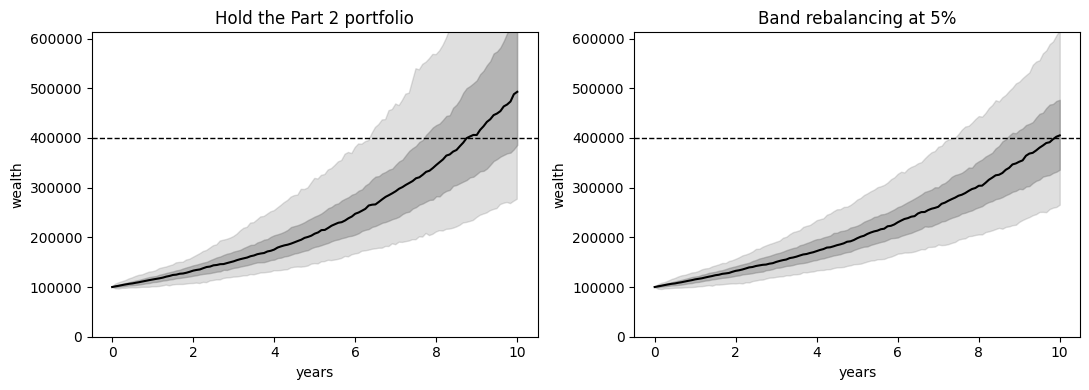

In [14]:
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
months = np.arange(config.HORIZON_MONTHS + 1) / 12.0
for axis, name in ((left, baseline_name), (right, SPECS[2][0])):
    paths = runs[name]["wealth_paths"]
    axis.fill_between(months, np.percentile(paths, 5, axis=0),
                      np.percentile(paths, 95, axis=0), alpha=0.25, color="grey")
    axis.fill_between(months, np.percentile(paths, 25, axis=0),
                      np.percentile(paths, 75, axis=0), alpha=0.45, color="grey")
    axis.plot(months, np.median(paths, axis=0), color="black")
    axis.axhline(reference, linestyle="--", linewidth=1.0, color="black")
    axis.set_xlabel("years")
    axis.set_ylabel("wealth")
    axis.set_title(name)
    axis.set_ylim(0, np.percentile(runs[baseline_name]["wealth_paths"], 97))
plt.tight_layout()
plt.savefig("results/figures/fan.png", dpi=120)
plt.show()

The two fans are drawn on the same vertical scale so the shapes can be compared directly. The band's is visibly narrower at every horizon and its upper edge is far lower, which is the same fact twice: restoring the target repeatedly sells whatever has just risen, and in a decade where the thing that rose kept rising, that is where the difference in median terminal wealth went. The dashed line is the client's target, and the share of each fan finishing below it is the shortfall column of the table above.

In [15]:
start_concentration = float((target ** 2).sum())
rows = []
for name, kind, make, start in SPECS:
    weights_at_end = runs[name]["terminal_weights"]
    concentration = float((weights_at_end ** 2).sum(1).mean())
    largest = weights_at_end.max(1)
    rows.append({"policy": name,
                 "effective holdings at the start": 1.0 / float((start ** 2).sum()),
                 "effective holdings at the end": 1.0 / concentration,
                 "largest weight, mean": largest.mean(),
                 "largest weight, 95th": np.percentile(largest, 95),
                 "largest weight, worst": largest.max(),
                 "keeps the cap at the 95th": np.percentile(largest, 95) <= config.MAX_POSITION})
drift = pd.DataFrame(rows)
print(drift.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print(f"\nthe Part 2 cap on any single holding is {config.MAX_POSITION:.0%}")

                    policy  effective holdings at the start  effective holdings at the end  largest weight, mean  largest weight, 95th  largest weight, worst  keeps the cap at the 95th
 Hold the Part 2 portfolio                            4.109                          2.118                 0.630                 0.818                  0.897                      False
        Hold equal weights                           25.000                         15.537                 0.141                 0.215                  0.385                       True
    Band rebalancing at 5%                            4.109                          4.030                 0.351                 0.391                  0.424                      False
   Re-solve every 6 months                            4.109                          3.721                 0.366                 0.416                  0.455                      False
      Panic selling at 15%                            4.109                

This is the table the recommendation turns on. Part 2 caps any single holding at 35%, and it imposes that cap once, at the moment the portfolio is built, while the objective never asks for it again, so nothing in the problem as posed prevents a policy from letting the weights drift straight through it.

They do. The portfolio is built with 4.1 effective holdings and a largest position of 34%, a single point inside the cap. Holding ends at 2.1 effective holdings, and equal weights, which never trades either, keeps 15.5 only because it started with twenty five equal holdings and no single fund can run away from the pack. The two behavioural rules end at 2.1 and 2.9, so neither of them protects the mandate.

The band and the re-solving model are the two that hold it, at 4.0 and 3.7 effective holdings, and the column to read is the 95th percentile of the largest weight rather than its mean or its worst case.

No policy keeps the largest holding under 35% outright, and none can. The optimiser places the portfolio within a point of the cap to begin with, and weights move between the dates a policy acts, so a test for never exceeding the cap would reject a rule that rebalances every month along with one that never does. What a policy can control is the overshoot, and the admissible ones are those that keep the largest holding within five percentage points of the cap at the 95th percentile. That bound is ours and section 7 lists it with the other decisions of the same kind.

In [16]:
disciplined = SPECS[2][0]
rows = []
for name in (SPECS[4][0], SPECS[5][0], SPECS[0][0]):
    difference = evaluate.paired_difference(runs[name]["terminal"], runs[disciplined]["terminal"])
    rows.append({"policy": name,
                 "median terminal wealth": np.median(runs[name]["terminal"]),
                 "median difference": difference["median"],
                 "mean difference": difference["mean"],
                 "CI low": difference["ci_low"], "CI high": difference["ci_high"],
                 "share of the disciplined median":
                     np.median(runs[name]["terminal"]) / np.median(runs[disciplined]["terminal"])})
behavioural = pd.DataFrame(rows)
print(f"measured against: {disciplined}")
print(behavioural.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

measured against: Band rebalancing at 5%
                    policy  median terminal wealth  median difference  mean difference      CI low     CI high  share of the disciplined median
      Panic selling at 15%             455,182.878         50,885.878       67,315.770  56,684.122  77,947.419                            1.124
Performance chasing at 0.5             474,260.323         61,966.789       79,831.153  72,559.107  87,103.198                            1.171
 Hold the Part 2 portfolio             492,805.521         83,970.235      115,328.950 105,233.302 125,424.599                            1.217


The brief asks for the cost of the client's tendencies as a change in median terminal wealth against disciplined rebalancing, and measured that way **both tendencies come out ahead** of the disciplined policy. Reporting that honestly matters more than reporting it comfortably, and the explanation is the one the drift table already gave: panic selling sits out of the market in a minority of scenarios and otherwise does nothing, performance chasing tilts toward a winner that kept winning, and both spend most of their time letting the portfolio drift, which is what paid in this decade.

The cost of the tendencies is real, but it is not visible in the median against a disciplined benchmark. It appears in three other places. Against what the client would otherwise have done, which is to hold, both tendencies lose on the objective, by 15,048 and 8,220 with intervals that exclude zero. It appears in the tail rather than the middle, since panic selling takes the fifth percentile from 276,615 down to 218,949, a gap of about 57,700 that neither figure states on its own, while the middle of the paired difference barely moves. And it appears once the trigger is set where a nervous client would really set it, which the sensitivity table below shows.

<a id="s5"></a>

## 5. Robustness, and what would change the recommendation

In [17]:
equal_means = data.equalise_means(R)
equal_paths = evaluate.scenarios(equal_means, config.N_EVAL, config.EVAL_SEED)
print(f"cross-sectional spread of annualised means: "
      f"sample {12 * R.mean(0).std():.4f}, equalised {12 * equal_means.mean(0).std():.4f}")

equal_runs = {name: simulator.run_policy(make, equal_paths, start, client, reference)
              for name, kind, make, start in SPECS}
rows = []
for name, kind, make, start in SPECS:
    difference = evaluate.paired_difference(equal_runs[name]["value"],
                                            equal_runs[baseline_name]["value"])
    rows.append({"policy": name, "class": kind,
                 "E[v]": equal_runs[name]["value"].mean(),
                 "median W": np.median(equal_runs[name]["terminal"]),
                 "difference against the baseline": difference["mean"],
                 "CI low": difference["ci_low"], "CI high": difference["ci_high"],
                 "significant": difference["significant"]})
equal_table = pd.DataFrame(rows).sort_values("E[v]", ascending=False)
print()
print(equal_table.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

cross-sectional spread of annualised means: sample 0.0601, equalised 0.0000



                    policy       class       E[v]   median W  difference against the baseline    CI low   CI high  significant
   Re-solve every 6 months         CFA -59,971.27 265,164.60                         1,328.13     77.06  2,579.21         True
    Band rebalancing at 5%         PFA -60,973.53 265,892.42                           325.87   -456.92  1,108.65        False
 Hold the Part 2 portfolio    baseline -61,299.40 263,140.07                             0.00      0.00      0.00        False
Performance chasing at 0.5 behavioural -61,808.71 261,136.18                          -509.31 -1,687.30    668.69        False
      Panic selling at 15% behavioural -62,600.35 262,001.97                        -1,300.95 -1,890.36   -711.55         True
        Hold equal weights    baseline -66,119.85 252,577.65                        -4,820.45 -6,322.41 -3,318.48         True


This is the experiment that tells us whether the ranking above is a property of the policies or of the decade. Every fund is given the same expected return, which removes a cross-sectional spread of 6.01% a year, while the covariance matrix and the month-to-month structure are left exactly as they were, so the scenarios differ from the main ones in one respect only: no fund carries a drift advantage over any other.

The 28,187 that doing nothing was worth disappears completely. The band now sits 326 above it with an interval of $[-456, 1{,}109]$, which is to say the two are indistinguishable, while the re-solving model moves from second place to first and beats holding by 1,328 with an interval of $[77, 2{,}579]$ that excludes zero. Nothing here says the band wins; it says the case against discipline was built entirely out of one decade's cross-section, and that with that cross-section removed discipline is free and re-optimising is better than free.

Two policies still lose once the drift advantage is gone, and both significantly. Panic selling loses 1,300 with an interval of $[-1{,}890, -711]$, so its cost is a property of the rule rather than of the sample, which is what one would expect of a rule that sits out of the market at the worst moments. Equal weights loses 4,820. We did not test why, and the plausible reading, that spreading equally across twenty five funds is worse on risk than the constrained optimisation once no fund has a return advantage, is an inference rather than a result.

In [18]:
rows = []
for multiple in (1.0,) + tuple(config.TARGET_MULTIPLES):
    rho = config.INITIAL_WEALTH * multiple
    for name, kind, make, start in SPECS:
        terminal = runs[name]["terminal"]
        rows.append({"target": f"{multiple:g}x",
                     "policy": name,
                     "E[v]": np.mean(simulator.objective(terminal, rho, client.alpha,
                                                         client.beta, client.lam)),
                     "misses target": (terminal < rho).mean()})
target_table = pd.DataFrame(rows).pivot(index="policy", columns="target", values="E[v]")
shortfall = pd.DataFrame(rows).pivot(index="policy", columns="target", values="misses target")
print("expected value of the objective, by target")
print(target_table.to_string(float_format=lambda v: f"{v:,.0f}"))
print()
print("share of scenarios that miss the target")
print(shortfall.to_string(float_format=lambda v: f"{v:.3f}"))

expected value of the objective, by target
target                         1x     2x     3x      4x
policy                                                 
Band rebalancing at 5%     68,796 48,857 25,900  -5,058
Hold equal weights         48,064 25,585 -5,968 -45,477
Hold the Part 2 portfolio  90,000 70,771 49,462  23,129
Panic selling at 15%       80,836 60,748 37,184   8,081
Performance chasing at 0.5 83,565 64,093 42,257  14,909
Re-solve every 6 months    84,508 65,112 43,432  16,745

share of scenarios that miss the target
target                        1x    2x    3x    4x
policy                                            
Band rebalancing at 5%     0.000 0.004 0.138 0.474
Hold equal weights         0.000 0.098 0.504 0.822
Hold the Part 2 portfolio  0.000 0.004 0.078 0.282
Panic selling at 15%       0.002 0.034 0.170 0.386
Performance chasing at 0.5 0.000 0.006 0.086 0.324
Re-solve every 6 months    0.000 0.004 0.088 0.302


The target is an input rather than a measurement, since the brief allows either the initial wealth or a target the client names, so the report quotes four of them and the first row is the initial wealth itself. Holding is the highest-scoring policy at every one, which says the ranking is not an artefact of the target that was picked.

What the target does change is whether loss aversion is doing anything at all. The shortfall column shows it. At a reference of the 100,000 invested no policy in the table puts any scenario below it, so the loss arm of the value function never activates and the $\lambda$ of 2.16 that the whole of Part 1 exists to measure has no effect on any ranking. At twice the initial wealth the shortfall is still small for the recommended portfolio and loss aversion barely registers. Only at four times does a third of holding's scenarios fall short, and more than half of the band's, so the parameter starts to carry weight, which is why the report leads with the four-times target.

In [19]:
rows = []
for d in config.PANIC_DRAWDOWN_GRID:
    out = simulator.run_policy(policies.panic_selling(target, cash, d, config.PANIC_RECOVERY),
                               eval_paths, target, client, reference)
    rows.append({"drawdown that triggers a sale": d,
                 "fires in": (out["months_traded"] > 0).mean(),
                 "median terminal wealth": np.median(out["terminal"]),
                 "E[v]": out["value"].mean(),
                 "worst fall": out["max_drawdown"].mean()})
panic_table = pd.DataFrame(rows)
print(panic_table.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

 drawdown that triggers a sale  fires in  median terminal wealth        E[v]  worst fall
                         0.100     0.908             335,867.336 -28,751.898       0.130
                         0.150     0.364             455,182.878   8,081.247       0.142
                         0.200     0.092             484,582.545  20,385.068       0.145
                         0.250     0.024             488,265.872  22,458.446       0.146


The trigger is the single most consequential number in the whole report and it is not one we measured, since the questionnaire detects the tendency without pinning the threshold. At 25% the rule fires in 2% of scenarios and costs nothing worth naming; at 15%, the value used above, it fires in 36% and the median is 455,183; at 10% it fires in 91% and the median falls to 335,867, against 492,805 for a client who never sells.

That last figure deserves to be set against the rebalancing question that occupies the rest of this report, and the comparison has to be made against the same baseline on both sides or it means nothing. The table above gives what each trigger costs against holding, and the gap between a 15% trigger and a 10% one is larger than the gap between holding and the recommended band. Either way the behaviour matters more than the policy, which is an uncomfortable conclusion for a report about policies and the right one to give the adviser.

<a id="s6"></a>

## 6. Recommendation to the client

**Re-solve the portfolio every six months, keep the 5% band as the simpler alternative, and treat the trigger that would make you sell as the more urgent problem of the three.**

The honest starting point is that the objective prefers the opposite. Holding the Part 2 portfolio and never trading scores 23,129 against the band's $-5{,}058$ and finishes with a median wealth of 492,805 against 405,091, and the interval around that difference excludes zero, so it is not noise. A recommendation has to answer that, not step around it.

It is answered by what the number leaves out. The portfolio was built under a constraint that no single fund exceed 35%, and that constraint was imposed once, while the objective never asks for it again. Holding ends with 2.1 effective holdings against the 4.1 it started with, so the policy that wins the objective wins it by abandoning the mandate, and an adviser cannot put that in front of a client who was profiled for something else.

Among the policies that do hold the mandate, the choice is between the band and the re-solving model, and **the re-solving model is the better of the two on every number that matters here**. It gives up 6,384 of objective against holding where the band gives up 28,188, it keeps 3.7 effective holdings against the band's 4.0, and it wins against holding in 41% of scenarios against the band's 5%. Discipline through a re-solved optimisation is roughly a quarter the price of discipline through a fixed band.

So the recommendation is the re-solving model, with the band as the simpler fallback for a client who wants a rule they can check themselves. What discipline costs, taken at the cheaper of the two, is 6,384 of objective with an interval of $[-8{,}055, -4{,}714]$. What it buys is a portfolio that ends with 3.7 effective holdings rather than 2.1. The client should be shown that trade in those terms and allowed to decline it.

One figure is easy to misread. The worst fall reported in the table is the average across scenarios of each path's own largest fall, not the largest fall anywhere, which is deeper for every policy.

Our confidence that the trade is worth taking rests on the robustness test rather than on the main table. When every fund is given the same expected return, the entire advantage of holding vanishes: the band becomes indistinguishable from it, at 326 with an interval of $[-456, 1{,}109]$, and the re-solving model beats it outright by 1,328 with an interval that excludes zero. The case for doing nothing was built out of one decade's cross-sectional spread of 6.01% a year, and a client is being asked to bet the next decade on it repeating. Re-optimising is the policy that does not need that bet to pay, and is the only one that is better off without it.

**What would change the recommendation.**

If the client genuinely has no mandate, and is content to end with most of their wealth in whichever fund happened to run, then holding is the better policy on every number in this report and should be recommended instead. The cap is a constraint we set as the advisory firm's, not a preference we measured, and a client who waives it is a different client.

If the spread of expected returns across funds is believed to be much smaller than the 6.01% a year this sample showed, which is what the course's own treatment of estimation error would suggest, then the cost of rebalancing is close to zero and the case becomes one-sided.

If the client's true panic threshold is nearer 10% than 15%, the advice changes shape entirely. At that trigger the rule fires in 91% of scenarios and takes the median to 335,867, against 492,805 for holding and 455,183 at the 15% trigger, which is a larger loss than the entire rebalancing decision is worth, so the adviser's effort belongs in pre-committing the client against selling rather than in choosing a band. This is the part of the recommendation that survives the robustness test, because panic selling is one of only two policies that still loses significantly once the drift advantage is removed, the other being equal weights, and it is the only one of the two that describes something the client would actually do.

<a id="s7"></a>

## 7. Limitations

**The scenarios inherit the sample they were drawn from.** The block bootstrap resamples the same 129 months used to estimate $\mu$ and $\Sigma$, so the expected returns inside the simulation are the sample's own, and no amount of simulation can reveal the estimation error that section 2.2 is about. Comparisons between policies remain valid, because every policy meets the same scenarios, while the level of terminal wealth is not a forecast: holding's median of 492,805 from 100,000 implies 17.3% a year and the recommended policy's 480,552 implies 17.0%, both of which describe 2016 to 2026 rather than the next ten years.

**Dependence longer than six months is destroyed.** Blocks of three to six months preserve whatever serial structure lives inside that window and nothing beyond it, so valuation-driven mean reversion over several years, if it exists, cannot appear in these scenarios. A policy that profits from it would be invisible here.

**One cost model, and nothing else.** Ten basis points on every peso traded, no taxes, no bid-ask spread that widens when it matters, no contributions or withdrawals over ten years, and perfect divisibility. A real client's ten years contain all of these.

**The profile is one administration, and loss aversion is not separately identified.** The ten questions were answered once, with no repetition to check stability, and the course's own treatment notes that published estimates range from 1.4 to 3.0 partly because elicitation methods disagree. The ladder brackets the switch point rather than locating it, so this client's value is a bracket midpoint and a finer ladder would move it. More fundamentally, the appendix of that lecture states that loss aversion and probability weighting cannot be separated from a single indifference, so the figure reported here is conditional on the weighting function being the published one, and an elicitation designed to cancel the weights would be needed to do better.

**The re-solving policy never learns.** It solves with the moments estimated at time zero, which keeps it free of lookahead but also means it cannot react to anything the simulated decade reveals. A version that re-estimated from the path would be a different policy and might rank differently.

**Five decisions are ours rather than the course's**, and each is stated where it is used as well as here, because a reader who disagrees with any of them should be able to find it and change it.

1. The map from loss aversion to the risk aversion of Part 2, linear between two anchors we chose.
2. The shrinkage intensity of 0.50 applied to the mean, where the course's own prescription is an explicit covariance target or a prior on returns.
3. The convention that the commission is charged on every unit traded rather than on the course's turnover, which is half that.
4. The mandate read as a standing constraint on the policy, with the overshoot bounded at five percentage points and checked at the 95th percentile across scenarios.
5. The ladder format of the loss-aversion question, where the lecture asks for the number directly, and the use of the bracket midpoint as the switch point.

Every one of them moves the answer, and the first, second and fourth move it most.

<a id="s8"></a>

## 8. References

- Tversky, A. and Kahneman, D. (1992). Advances in prospect theory: cumulative representation of uncertainty. *Journal of Risk and Uncertainty*, 5(4), 297–323. The value function, the weighting function and the parameter estimates used throughout Part 1.
- Odean, T. (1998). Are investors reluctant to realize their losses? *The Journal of Finance*, 53(5), 1775–1798. The disposition effect, which question 8 of the instrument detects.
- Markowitz, H. (1952). Portfolio selection. *The Journal of Finance*, 7(1), 77–91. The objective of Part 2.
- Michaud, R. (1989). The Markowitz optimization enigma: is optimized optimal? *Financial Analysts Journal*, 45(1), 31–42. Why the optimiser prefers assets carrying positive estimation error.
- Merton, R. (1980). On estimating the expected return on the market. *Journal of Financial Economics*, 8(4), 323–361. Why the mean cannot be estimated precisely from any feasible sample.
- Chopra, V. and Ziemba, W. (1993). The effect of errors in means, variances and covariances on optimal portfolio choice. *Journal of Portfolio Management*, 19(2), 6–11.
- Jagannathan, R. and Ma, T. (2003). Risk reduction in large portfolios: why imposing the wrong constraints helps. *The Journal of Finance*, 58(4), 1651–1683. Why the shrinkage is explicit here.
- DeMiguel, V., Garlappi, L. and Uppal, R. (2009). Optimal versus naive diversification. *Review of Financial Studies*, 22(5), 1915–1953. Why equal weights is carried as a second baseline.
- Powell, W. B. (2022). *Reinforcement Learning and Stochastic Optimization: A Unified Framework for Sequential Decisions*. Wiley. The five elements, the four policy classes and the six-step process.
- Course material: decks 002 mean variance, 003 Prospect Theory, 005 SDA, 007 Policy Classes and 008 PFA and CFA, and the notebooks `Portfolio Optimization.ipynb` and `008 - PFA - CFA 2.ipynb`.